# Oriented stacking on cosmic filaments

This tutorial stacks a map on the points of a filament catalogue, with each patch rotated so that the filament lies along the same axis. It uses an SDSS galaxy overdensity map, where the filaments are known to be there. A clear ridge in the stack therefore validates the positions, the angle convention and the patch geometry before stacking fields with a much weaker signal, such as CMB lensing.

It uses the parts of `cmbstack` meant for stacking on a catalogue:

- `positions` and `psi`, to stack on given sky positions with a rotation for each patch
- rectangular patches (`size_deg`, `size_deg_y`), with sizes converted from Mpc with `size_mpc_to_deg`
- `iter_patches` and `stack_patches`, which stream the patches so that a catalogue of millions of points fits in memory

Besides `cmbstack`, it needs `pandas` and `astropy` (`pip install pandas astropy`).

## Data

**Filament catalogue.** The catalogue of [Carrón Duque et al. (2022)](https://doi.org/10.1051/0004-6361/202141538), built from SDSS DR16 with the tomographic SCMS method, is available from [the author's website](https://www.javiercarron.com/catalogue). This tutorial uses `Block1.csv`. Each row is a filament point in a redshift slice `[z_low, z_high)`, with columns including `RA`, `dec` (degrees), `angle` (degrees) and the slice limits.

**Galaxies.** The overdensity map is built from SDSS DR16 spectroscopic galaxies. Any table with the columns `RA`, `DEC` (degrees), `Z` and `CLASS` works; edit `load_galaxies` for another format.

Put both files in `data_dir`:

In [1]:
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
import pandas as pd

from astropy.cosmology import Planck18 as cosmo

from cmbstack import stacking

In [2]:
data_dir = 'data'
catalogue_fname = data_dir + '/Block1.csv'
galaxy_fname = data_dir + '/sdss_dr16_galaxies.pkl'

## Helper functions

The galaxy map is built separately for each redshift slice of the catalogue, from the galaxies in that slice only:

- The footprint is the set of $N_{side} = 64$ pixels holding at least one galaxy, at any redshift.
- The overdensity is $\delta_g = n / \bar n - 1$, with $\bar n$ the mean number of galaxies per pixel inside the footprint. Pixels outside it are `hp.UNSEEN`, so they are ignored in the stack.

The patches have the same physical size at every redshift. `slice_geometry` converts it to degrees at the centre of the slice, and picks the resolution so that every slice has the same number of pixels and the patches can be added together.

In [3]:
def select_z(filaments, z):
    '''Returns the filament points of the redshift slice containing z.'''
    return filaments[(filaments['z_low'] <= z) & (filaments['z_high'] > z)]


def load_galaxies(fname, z_min=0.03, z_max=0.48):
    '''Loads the galaxy table and keeps galaxies (no QSOs) with z_min < Z < z_max.'''
    gal = pd.read_pickle(fname)
    keep = (gal['CLASS'] == 'GALAXY') & (gal['Z'] > z_min) & (gal['Z'] < z_max)
    return gal[keep].reset_index(drop=True)


def galaxy_footprint(gal, nside_fp=64, nside=512):
    '''Boolean footprint (True = observed) at `nside`: the Nside `nside_fp` pixels holding at least one galaxy.

    Built from all redshifts at once, so pixels that happen to be empty in a thin slice still count as observed.
    '''
    fp = np.zeros(hp.nside2npix(nside_fp), dtype=bool)
    fp[hp.ang2pix(nside_fp, gal['RA'].to_numpy(), gal['DEC'].to_numpy(), lonlat=True)] = True
    return hp.ud_grade(fp.astype(float), nside) > 0.5


def overdensity_map(gal, z_lo, z_hi, footprint):
    '''Galaxy overdensity delta = n / nbar - 1 for galaxies with z_lo <= Z < z_hi.

    nbar is the mean count per pixel inside the footprint. Pixels outside the footprint are UNSEEN.
    Returns the map and the number of galaxies used.
    '''
    nside = hp.get_nside(footprint)
    g = gal[(gal['Z'] >= z_lo) & (gal['Z'] < z_hi)]
    pix = hp.ang2pix(nside, g['RA'].to_numpy(), g['DEC'].to_numpy(), lonlat=True)
    n = np.bincount(pix, minlength=hp.nside2npix(nside)).astype(float)
    nbar = n[footprint].mean()
    delta = np.full(n.size, hp.UNSEEN)
    delta[footprint] = n[footprint] / nbar - 1
    return delta, len(g)


def slice_geometry(z, size_x, size_y, ny):
    '''Patch sizes in degrees and resolution in arcmin, so every slice has ny pixels along size_y.'''
    size_deg_x = stacking.size_mpc_to_deg(size_x, z, cosmo)
    size_deg_y = stacking.size_mpc_to_deg(size_y, z, cosmo)
    return size_deg_x, size_deg_y, size_deg_y * 60 / ny


def slice_patches(catalogue, gal, footprint, size_x, size_y, ny):
    '''Generator: for each redshift slice, builds its galaxy overdensity map and yields its patches.'''
    for (z_low, z_high), s in catalogue.groupby(['z_low', 'z_high']):
        delta, _ = overdensity_map(gal, z_low, z_high, footprint)
        size_deg_x, size_deg_y, reso = slice_geometry(0.5 * (z_low + z_high), size_x, size_y, ny)
        yield from stacking.iter_patches(delta, s[['RA', 'dec']].to_numpy(), psi=s['angle'].to_numpy(),
                                         size_deg=size_deg_x, size_deg_y=size_deg_y, reso_arcmin=reso)


def plot_stack(stack, counts, size_x, size_y, title):
    '''Stack and count map, with the filament direction (patch x) vertical.'''
    extent = [-size_y/2, size_y/2, -size_x/2, size_x/2]
    vmax = np.nanmax(np.abs(stack))
    fig, axs = plt.subplots(2, 1, figsize=(10, 6))
    im = axs[0].imshow(stack.T, origin='lower', extent=extent, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    axs[0].set_title(title)
    fig.colorbar(im, ax=axs[0], label=r'$\delta_g$')
    im = axs[1].imshow(counts.T, origin='lower', extent=extent, cmap='Greys')
    axs[1].set_title('Number of patches contributing to each pixel')
    fig.colorbar(im, ax=axs[1])
    for ax in axs:
        ax.set_xlabel('across filament [Mpc]')
        ax.set_ylabel('along [Mpc]')
    plt.tight_layout()
    plt.show()

## Load the data

In [4]:
nside = 512                 # galaxy map resolution (6.9')
size_x, size_y = 40, 200    # patch size in Mpc: x along the filament, y across it
ny = 240                    # pixels along size_y (48 along size_x)

catalogue = pd.read_csv(catalogue_fname, index_col=0)
gal = load_galaxies(galaxy_fname)
footprint = galaxy_footprint(gal, nside=nside)

print(f'{len(catalogue):,} filament points in {catalogue.groupby(["z_low", "z_high"]).ngroups} slices')
print(f'{len(gal):,} galaxies with 0.03 < z < 0.48')
print(f'galaxy footprint: {footprint.mean():.1%} of the sky')

1,920,003 filament points in 78 slices
1,562,518 galaxies with 0.03 < z < 0.48
galaxy footprint: 27.7% of the sky


## One redshift slice

The slice containing $z = 0.3$ is used first. The overdensity map is noisy, with fewer than one galaxy per pixel, so it is smoothed here only to show the filaments following the galaxies:

slice [0.296, 0.302): 13,767 galaxies, 24,836 filament points


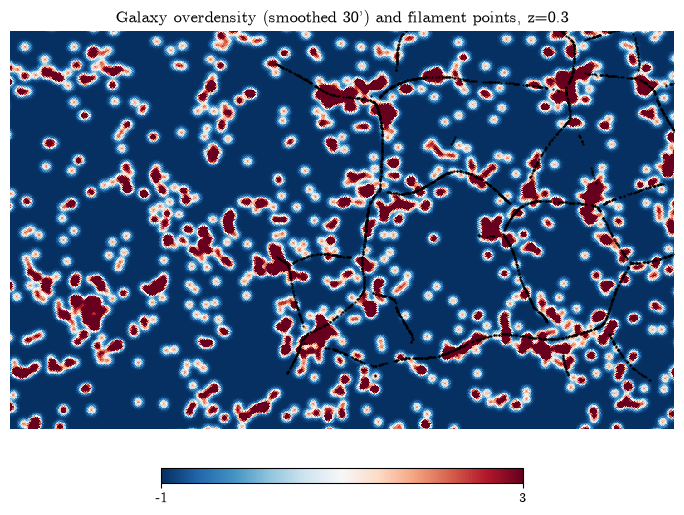

In [5]:
z = 0.3
sliced = select_z(catalogue, z)
z_low, z_high = sliced['z_low'].iloc[0], sliced['z_high'].iloc[0]
delta, n_gal = overdensity_map(gal, z_low, z_high, footprint)
print(f'slice [{z_low}, {z_high}): {n_gal:,} galaxies, {len(sliced):,} filament points')

delta_sm = hp.smoothing(np.where(footprint, delta, 0.0), fwhm=np.radians(0.5))
delta_sm[~footprint] = hp.UNSEEN
hp.cartview(delta_sm, lonra=[150, 200], latra=[0, 30], cmap='RdBu_r', min=-1, max=3,
            title=f"Galaxy overdensity (smoothed 30') and filament points, z={z}")
hp.projscatter(sliced['RA'].values, sliced['dec'].values, s=0.3, c='k', lonlat=True)
plt.show()

### Angle convention

The catalogue defines `angle` as the angle of the filament with the parallels of the sphere, measured counter-clockwise, that is, from east towards north. `extract_patches` and `iter_patches` rotate each patch by `psi` degrees in the same sense, so **`psi = angle` puts every filament along the x axis of its patch**.

The catalogue positions and angles are in equatorial coordinates, so the galaxy map is built in equatorial coordinates too. For a map in Galactic coordinates, such as the Planck maps, the positions have to be converted, and the angle rotated by the position angle of equatorial north measured in the Galactic frame.

The patch is 40 Mpc along the filament and 200 Mpc across it:

patch: 2.42 x 12.11 deg, 3.03 arcmin per pixel


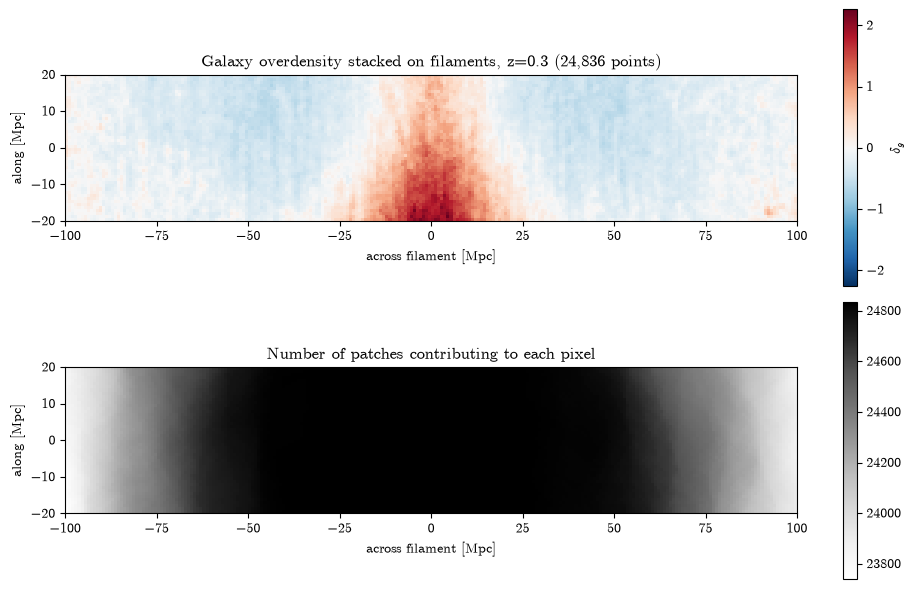

In [6]:
size_deg_x, size_deg_y, reso = slice_geometry(0.5 * (z_low + z_high), size_x, size_y, ny)
print(f'patch: {size_deg_x:.2f} x {size_deg_y:.2f} deg, {reso:.2f} arcmin per pixel')

positions = sliced[['RA', 'dec']].to_numpy()
angle = sliced['angle'].to_numpy()

def stack_slice(psi):
    patches = stacking.iter_patches(delta, positions, psi=psi, size_deg=size_deg_x,
                                    size_deg_y=size_deg_y, reso_arcmin=reso)
    return stacking.stack_patches(patches, return_counts=True)

slice_stack, slice_counts = stack_slice(angle)
plot_stack(slice_stack, slice_counts, size_x, size_y,
           f'Galaxy overdensity stacked on filaments, z={z} ({len(sliced):,} points)')

The stack shows a ridge along the filament, with negative flanks on either side: the voids that the filament separates. The count map is lower near the edges of the patch, where some patches leave the galaxy footprint.

### Controls

Two checks on the same slice show that the ridge comes from the orientation:

- **Shuffled `psi`:** the angles are randomly reassigned between the points. The ridge becomes a round blob, because the filaments no longer line up.
- **`psi = angle + 180`:** every patch is rotated by half a turn. The stack is mirrored along the filament. The catalogue angle runs from 0 to 360°, so it is a direction rather than just an axis, and the overdensity rises towards one end of the filament.

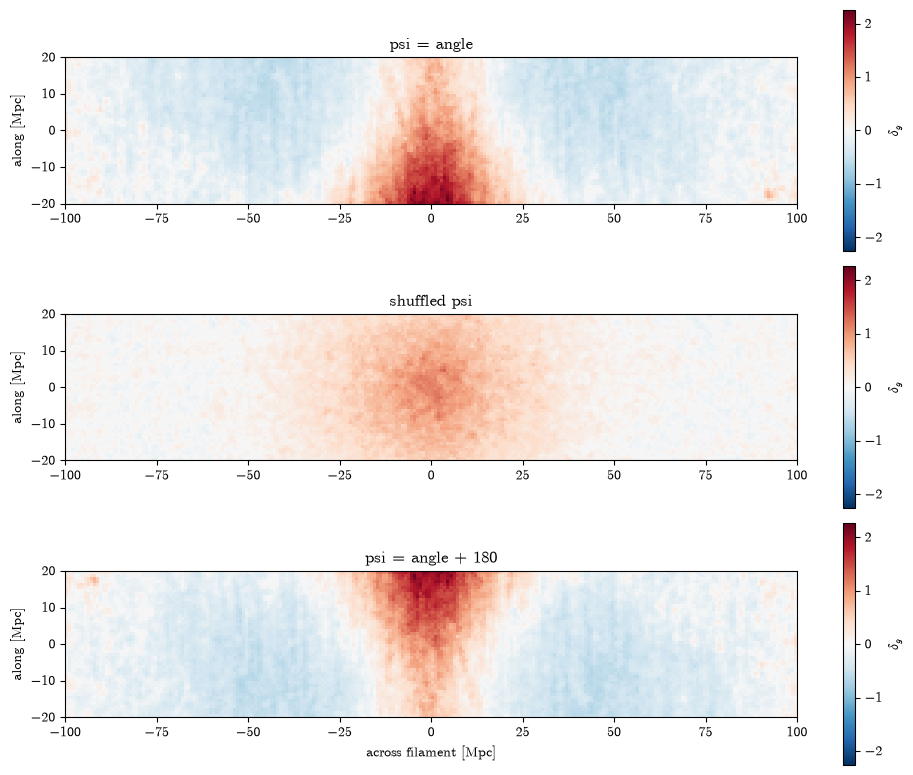

In [7]:
rng = np.random.default_rng(0)
shuffled_stack, _ = stack_slice(rng.permutation(angle))
flipped_stack, _ = stack_slice(angle + 180)

extent = [-size_y/2, size_y/2, -size_x/2, size_x/2]
vmax = np.nanmax(np.abs(slice_stack))
fig, axs = plt.subplots(3, 1, figsize=(10, 8))
for ax, s, t in zip(axs, [slice_stack, shuffled_stack, flipped_stack],
                    ['psi = angle', 'shuffled psi', 'psi = angle + 180']):
    im = ax.imshow(s.T, origin='lower', extent=extent, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.set_title(t)
    ax.set_ylabel('along [Mpc]')
    fig.colorbar(im, ax=ax, label=r'$\delta_g$')
axs[-1].set_xlabel('across filament [Mpc]')
plt.tight_layout()
plt.show()

## All redshift slices

`slice_patches` is a generator: it builds the galaxy map of one slice at a time and yields its patches. Passed straight to `stack_patches`, it stacks all the points of the block while keeping only one map and one patch in memory. This takes about 10 minutes for the 1.9 million points of block 1.

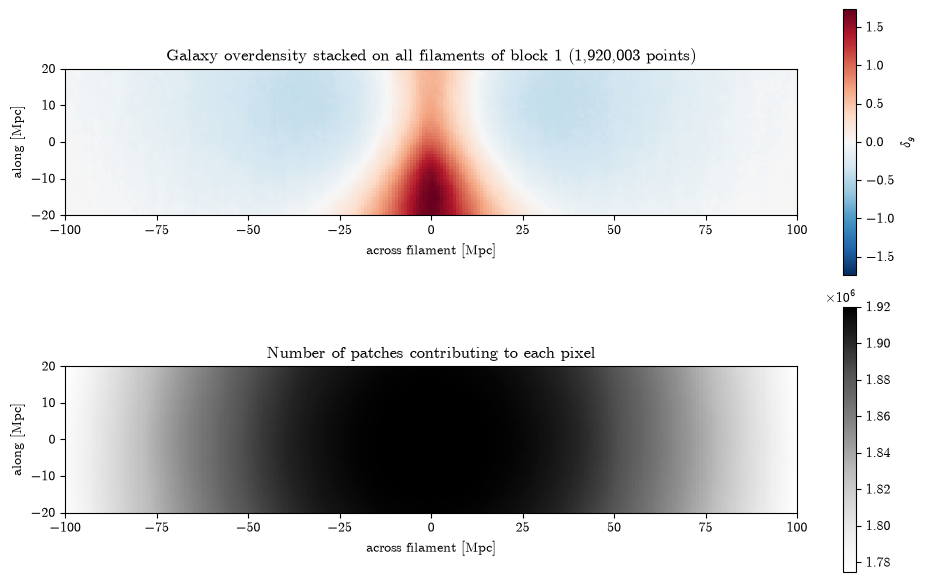

In [8]:
block_stack, block_counts = stacking.stack_patches(
    slice_patches(catalogue, gal, footprint, size_x, size_y, ny), return_counts=True)

plot_stack(block_stack, block_counts, size_x, size_y,
           f'Galaxy overdensity stacked on all filaments of block 1 ({len(catalogue):,} points)')

## Transverse profile

Averaging the stack along the filament gives the profile across it:

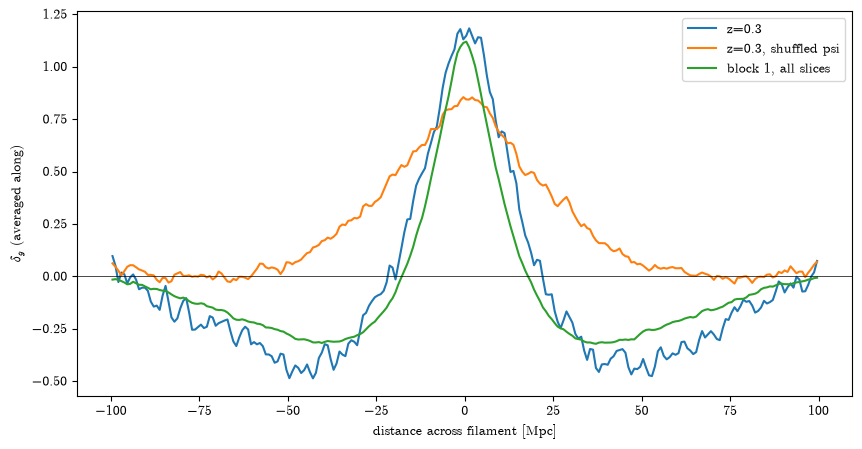

In [9]:
def transverse_profile(stack, size_y):
    '''Mean of the stack along the filament (patch x), against the distance across it in Mpc.'''
    ny = stack.shape[0]
    y = (np.arange(ny) + 0.5) * size_y / ny - size_y / 2
    return y, np.nanmean(stack, axis=1)

fig, ax = plt.subplots(figsize=(10, 5))
for s, label in [(slice_stack, f'z={z}'), (shuffled_stack, f'z={z}, shuffled psi'), (block_stack, 'block 1, all slices')]:
    y, profile = transverse_profile(s, size_y)
    ax.plot(y, profile, label=label)
ax.axhline(0, c='k', lw=0.5)
ax.set_xlabel('distance across filament [Mpc]')
ax.set_ylabel(r'$\delta_g$ (averaged along)')
ax.legend()
plt.show()